# IEEE 37-bus modified one-shot DDPG training and reference comparison

## Purpose

This notebook trains, evaluates, or views one-shot DDPG runs against neutral taps and native RegControl. Each hourly scenario is independent and starts from neutral taps. Results describe this saved validation split and synthetic process; they do not establish convergence or general performance.

In [1]:
from pathlib import Path
import sys

ROOT = Path.cwd().parents[1]
if not (ROOT / "src/feeder").is_dir():
    raise RuntimeError("Start the kernel in the notebook directory (experiments/<feeder>/).")
sys.path.insert(0, str(ROOT / "src"))

from common.reports import show_conclusions, show_controller_comparison, show_paired_counts, show_tap_sample, show_training_summary
from common.workflow import run_experiment

print("Repository root resolved.")

Repository root resolved.


## Parameters

Edit this cell, then restart the kernel and run all cells. `MODE` selects `train`, `evaluate`, or read-only `view`; `OVERWRITE` affects only writing modes. The former `TRAIN = True` maps to `MODE = "train"`, while `TRAIN = False` with evaluation maps to `MODE = "evaluate"`; use `view` for saved results.

In [2]:
FEEDER = "ieee37mod"  # Named feeder.
DATASET = "ieee37mod-random"  # Named dataset.
SEEDS = [0, 1, 2]  # Independent training seeds.
MODE = "view"  # train, evaluate, or read saved results.
OVERWRITE = False  # Applies only to train and evaluate.
EPISODES = 20000  # Training only: interactions per run.
SPLIT = "validation"  # Evaluation split.
EVALUATION_DAYS = None  # Complete split or a positive day limit.
REWARD = "band"  # Training only: reward name.
REWARD_PARAMETERS = {}  # Training only: overrides of the reward defaults.
RUN_NAME = "band"  # Run directory name before _seed<seed>.

**Units and interfaces.** Solver voltages and executed tap ratios use physical p.u. values; tap positions are integer grid indices. The network receives normalized voltage features. The selected reward is dimensionless, while reported voltage cost is mean squared excursion outside [0.95, 1.05] p.u.

In [3]:
results = run_experiment({
    "protocol": "one_shot",
    "algorithm": "ddpg",
    "feeder": FEEDER,
    "dataset": DATASET,
    "seeds": SEEDS,
    "mode": MODE,
    "overwrite": OVERWRITE,
    "episodes": EPISODES,
    "split": SPLIT,
    "evaluation_days": EVALUATION_DAYS,
    "reward": REWARD,
    "reward_parameters": REWARD_PARAMETERS,
    "run_name": RUN_NAME,
    "root": ROOT,
})

Dataset: ieee37mod-random (data/scenarios/ieee37mod-random)
Split: validation
Evaluated: 200 days, 4800 hours
Seeds: [0, 1, 2]
Reward: band {'beta': 0.0, 'deviation': 'abs', 'alpha': 0.0, 'rate': 20.0, 'voltage_min': 0.95, 'voltage_max': 1.05, 'scale': 1000.0}
Display names and run directories:
  DDPG seed 0: results/ieee37mod-random/ddpg/band_seed0/
  DDPG seed 1: results/ieee37mod-random/ddpg/band_seed1/
  DDPG seed 2: results/ieee37mod-random/ddpg/band_seed2/
  Neutral: results/ieee37mod-random/reference/neutral/
  RegControl: results/ieee37mod-random/reference/regcontrol/
Mode: view
Overwrite: False
Preflight passed. No subprocess has started before this point.
Using existing saved results. View mode launches no subprocess.
Scenario alignment passed for 4800 hours and 5 methods.


## Training records

An episode is one independent scenario and action. “Training voltage cost per scenario” shows the smoothed seed mean of the fixed evaluation cost on training episodes.

Training includes exploration; these curves are not held-out performance or proof of convergence.

Run,Reward,Reward parameters,Benchmark beta,Layer sizes,Completed training episodes,Update counts
DDPG seed 0,band,"{'beta': 0.0, 'deviation': 'abs', 'alpha': 0.0, 'rate': 20.0, 'voltage_min': 0.95, 'voltage_max': 1.05, 'scale': 1000.0}",None,"[400, 300]",20000,unavailable
DDPG seed 1,band,"{'beta': 0.0, 'deviation': 'abs', 'alpha': 0.0, 'rate': 20.0, 'voltage_min': 0.95, 'voltage_max': 1.05, 'scale': 1000.0}",None,"[400, 300]",20000,unavailable
DDPG seed 2,band,"{'beta': 0.0, 'deviation': 'abs', 'alpha': 0.0, 'rate': 20.0, 'voltage_min': 0.95, 'voltage_max': 1.05, 'scale': 1000.0}",None,"[400, 300]",20000,unavailable


Completed training episodes: {'band_seed0': 20000, 'band_seed1': 20000, 'band_seed2': 20000}


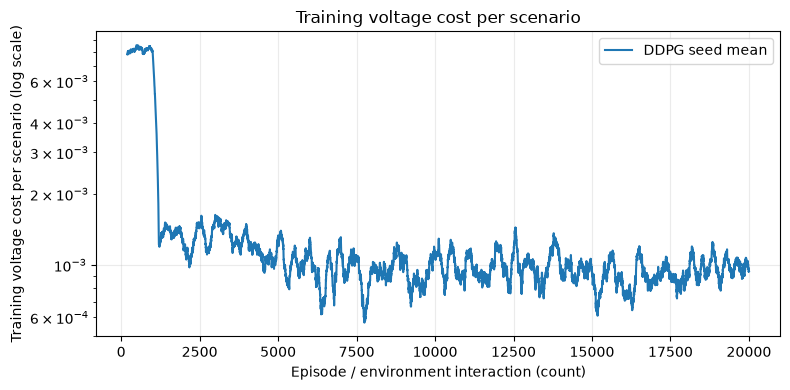

Cost uses the fixed evaluation metric on training episodes and includes exploration. It is not held-out performance or proof of convergence.

In [4]:
show_training_summary(results);


## Overall comparison

Every method uses the same ordered scenarios. Feasibility means convergence with every monitored voltage inside [0.95, 1.05] p.u.; violation count counts measurements, not hours. Across-seed sample standard deviation describes run-level spread, not a confidence interval.

Neutral holds every regulator ratio at 1.0. RegControl uses the feeder's native regulator control.

Hourly voltage cost is the mean squared excursion outside [0.95, 1.05] p.u. over 117 monitored line-line voltage measurements; in-band measurements contribute zero. Lower cost is better.

Method,Mean hourly voltage cost,Mean absolute deviation (p.u.),Feasible scenarios (%),Mean violating voltage measurements/scenario,Scenarios
DDPG seed 0,1.403e-04,2.7785e-02,16.3,22.37,4800
DDPG seed 1,1.413e-04,3.0201e-02,15.2,23.80,4800
DDPG seed 2,1.468e-04,3.2319e-02,18.2,25.43,4800
Neutral,3.033e-03,9.4211e-02,0.0,107.57,4800
RegControl,2.674e-04,3.4106e-02,10.9,33.17,4800


DDPG statistic,Mean hourly voltage cost,Mean absolute deviation (p.u.),Feasible scenarios (%),Mean violating voltage measurements/scenario
Across-seed mean,1.428e-04,3.0102e-02,16.6,23.87
Sample standard deviation,3.489e-06,2.2688e-03,1.5,1.53


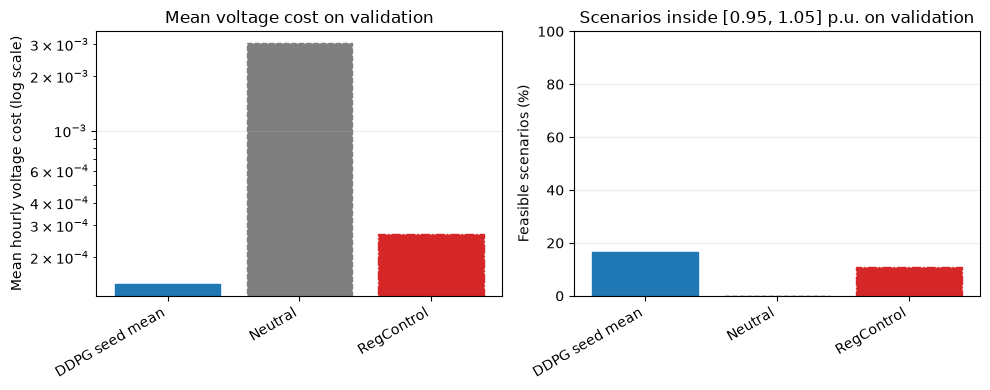

The voltage-cost panel uses a log scale because every displayed cost is positive. Log spacing shows multiplicative differences.

In [5]:
show_controller_comparison(results);


### Executed tap settings

Ratios are executed regulator settings, not bus voltages. Neutral is 1.0; legal ratios span 0.90 to 1.10 in 0.00625 steps. The five loading ranks are illustrative rather than aggregate evidence.

Scenario,Loading multiplier,Method,Ratio 1,Ratio 2,Ratio 3,Ratio 4,Ratio 5
validation-0128-h15,0.500193,DDPG seed 0,1.05625,1.0375,1.00625,0.98125,1.00625
validation-0128-h15,0.500193,DDPG seed 1,1.04375,1.0625,0.9875,1,1.03125
validation-0128-h15,0.500193,DDPG seed 2,1.0375,1.04375,1.00625,0.9875,1.00625
validation-0128-h15,0.500193,Neutral,1,1,1,1,1
validation-0128-h15,0.500193,RegControl,1.05,1.0375,1.01875,0.99375,1.04375
validation-0013-h10,0.747177,DDPG seed 0,1.09375,1.075,1.00625,0.975,1.0125
validation-0013-h10,0.747177,DDPG seed 1,1.0875,1.08125,1.00625,1,1.025
validation-0013-h10,0.747177,DDPG seed 2,1.075,1.04375,1.0125,0.99375,1.01875
validation-0013-h10,0.747177,Neutral,1,1,1,1,1
validation-0013-h10,0.747177,RegControl,1.1,1.06875,1.00625,0.99375,1.1


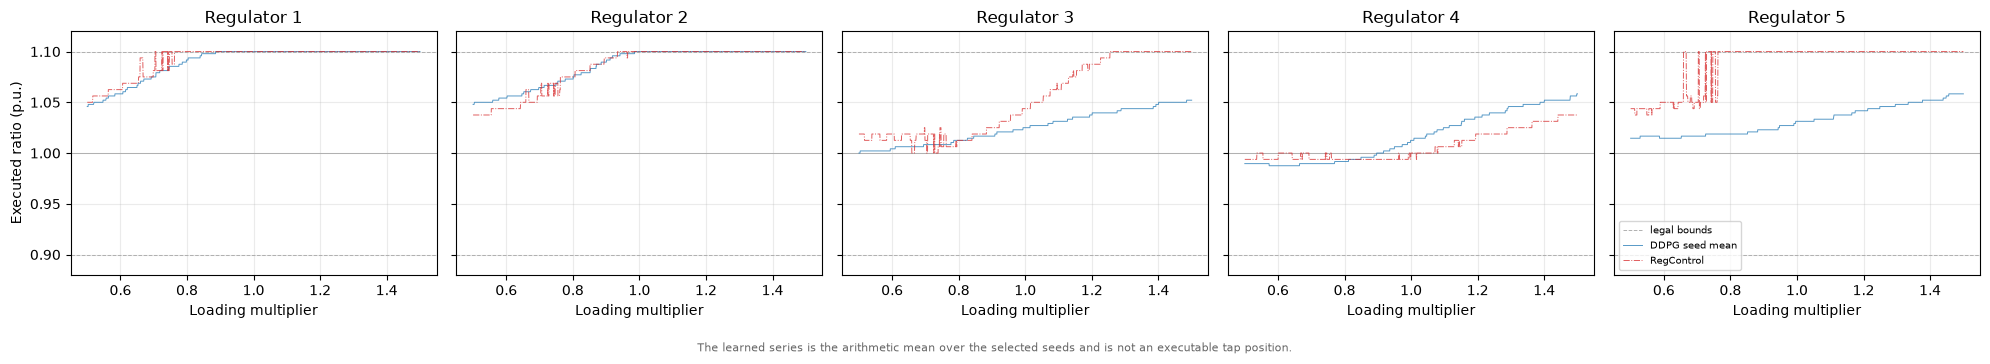

The learned series is the arithmetic mean over the selected seeds and is not an executable tap position.

The x-axis orders independent scenarios by loading multiplier, not time. Connecting lines aid reading; they are not trajectories or continuous actions.

In [6]:
show_tap_sample(results);


### Paired cost counts

Counts compare exact saved voltage costs on matched scenarios. Equality is exact, not a practical-equivalence test, and counts do not show improvement size.

In [7]:
show_paired_counts(results)

DDPG run,Reference,Lower-cost scenarios,Equal-cost scenarios,Higher-cost scenarios
DDPG seed 0,Neutral,4800,0,0
DDPG seed 0,RegControl,4278,522,0
DDPG seed 1,Neutral,4800,0,0
DDPG seed 1,RegControl,4278,522,0
DDPG seed 2,Neutral,4800,0,0
DDPG seed 2,RegControl,4278,522,0


## Conclusions

In [8]:
show_conclusions(results)

The validation evaluation covers 4800 independent scenarios for 3 DDPG seeds and 20000 training episodes per seed.

Across 3 independent seeds, DDPG mean hourly voltage cost is 1.428e-04 with sample standard deviation 3.489e-06. This is lower than Neutral (3.033e-03) and lower than RegControl (2.674e-04).

Across 3 independent seeds, DDPG feasible scenarios average 16.6% with sample standard deviation 1.5 percentage points; this is higher than Neutral (0.0%) and higher than RegControl (10.9%).

These results are limited to the validation split, this synthetic process, and the recorded training budget.